In [2]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root from this notebook's location.
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"

prices_path = DATA_DIR / "nifty50_processed.csv"
news_path = DATA_DIR / "news_processed.csv"
sentiment_path = DATA_DIR / "news_sentiment.csv"

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", DATA_DIR)

print("Price file exists:", prices_path.exists())
print("News file exists:", news_path.exists())
print("Sentiment file exists:", sentiment_path.exists())


Project directory: C:\Users\surya\Documents\finance-IDC-Project
Processed data directory: C:\Users\surya\Documents\finance-IDC-Project\data\processed
Price file exists: True
News file exists: True
Sentiment file exists: True


In [3]:
#loading the datasets


prices = pd.read_csv(prices_path, parse_dates=["Date"])

news = pd.read_csv(news_path)
sentiment = pd.read_csv(sentiment_path)

print("Prices:", prices.shape)
print("News:", news.shape)
print("News with sentiment:", sentiment.shape)

display(prices.head())
display(news.head())
display(sentiment.head())


Prices: (1234, 9)
News: (266, 5)
News with sentiment: (266, 10)


,Date,Close,High,Low,Open,Volume,return_1d,volatility_5d,volume_change
0,2021-10-22,18114.900391,18314.250000,18034.349609,18230.699219,324700.0,NaN,NaN,NaN
1,2021-10-25,18125.400391,18241.400391,17968.500000,18229.500000,418700.0,0.000580,NaN,0.289498
2,2021-10-26,18268.400391,18310.449219,18099.300781,18154.500000,341400.0,0.007889,NaN,-0.184619
3,2021-10-27,18210.949219,18342.050781,18167.900391,18295.849609,335200.0,-0.003145,NaN,-0.018161
4,2021-10-28,17857.250000,18190.699219,17799.449219,18187.650391,374200.0,-0.019422,NaN,0.116348


,title,published_at,source,url,collected_at
0,"Business News: Stock and Share Market News, Ec...",2006-03-14 22:24:39+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiQ0FVX...,2026-10-22T17:59:53.898988+00:00
1,Stock Market: Stock Market Today | Stock Marke...,2011-01-09 21:42:24+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiXEFVX...,2026-10-22T17:59:53.898988+00:00
2,NSE - National Stock Exchange of India Ltd: Li...,2014-07-25 05:11:21+00:00,NSE India,https://news.google.com/rss/articles/CBMiPkFVX...,2026-10-22T17:59:53.898988+00:00
3,"Share Market Live, Share Market Today: Latest ...",2016-06-02 11:21:42+00:00,The Economic Times,https://news.google.com/rss/articles/CBMiV0FVX...,2026-10-22T17:59:53.898988+00:00
4,"Investing.com India - Financial News, Shares &...",2017-01-08 08:56:04+00:00,Investing.com India,https://news.google.com/rss/articles/CBMiPkFVX...,2026-10-22T17:59:53.898988+00:00


,title,published_at,source,url,collected_at,sentiment_positive,sentiment_neutral,sentiment_negative,sentiment_compound,sentiment_label
0,"Business News: Stock and Share Market News, Ec...",2006-03-14 22:24:39+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiQ0FVX...,2026-10-22T17:59:53.898988+00:00,0.182,0.818,0.0,0.5994,unclassified
1,Stock Market: Stock Market Today | Stock Marke...,2011-01-09 21:42:24+00:00,Moneycontrol.com,https://news.google.com/rss/articles/CBMiXEFVX...,2026-10-22T17:59:53.898988+00:00,0.000,1.000,0.0,0.0000,unclassified
2,NSE - National Stock Exchange of India Ltd: Li...,2014-07-25 05:11:21+00:00,NSE India,https://news.google.com/rss/articles/CBMiPkFVX...,2026-10-22T17:59:53.898988+00:00,0.000,1.000,0.0,0.0000,unclassified
3,"Share Market Live, Share Market Today: Latest ...",2016-06-02 11:21:42+00:00,The Economic Times,https://news.google.com/rss/articles/CBMiV0FVX...,2026-10-22T17:59:53.898988+00:00,0.328,0.672,0.0,0.7783,unclassified
4,"Investing.com India - Financial News, Shares &...",2017-01-08 08:56:04+00:00,Investing.com India,https://news.google.com/rss/articles/CBMiPkFVX...,2026-10-22T17:59:53.898988+00:00,0.180,0.820,0.0,0.2960,unclassified


In [4]:

print("PRICE DATA")
display(prices.info())
print("\nMissing values:")
display(prices.isna().sum())

print("\nDuplicate price dates:", prices["Date"].duplicated().sum())

print("\nNEWS DATA")
print("Missing values:")
display(news.isna().sum())

print("\nDuplicate news URLs:", news["url"].duplicated().sum())

print("\nSENTIMENT LABEL COUNTS")
display(sentiment["sentiment_label"].value_counts(dropna=False))


PRICE DATA
<class 'pandas.DataFrame'>
RangeIndex: 1234 entries, 0 to 1233
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           1234 non-null   datetime64[us]
 1   Close          1234 non-null   float64       
 2   High           1234 non-null   float64       
 3   Low            1234 non-null   float64       
 4   Open           1234 non-null   float64       
 5   Volume         1234 non-null   float64       
 6   return_1d      1233 non-null   float64       
 7   volatility_5d  1229 non-null   float64       
 8   volume_change  1231 non-null   float64       
dtypes: datetime64[us](1), float64(8)
memory usage: 86.9 KB


None


Missing values:


Date             0
Close            0
High             0
Low              0
Open             0
Volume           0
return_1d        1
volatility_5d    5
volume_change    3
dtype: int64


Duplicate price dates: 0

NEWS DATA
Missing values:


title           0
published_at    0
source          0
url             0
collected_at    0
dtype: int64


Duplicate news URLs: 0

SENTIMENT LABEL COUNTS


sentiment_label
positive        106
neutral         100
negative         54
unclassified      6
Name: count, dtype: int64

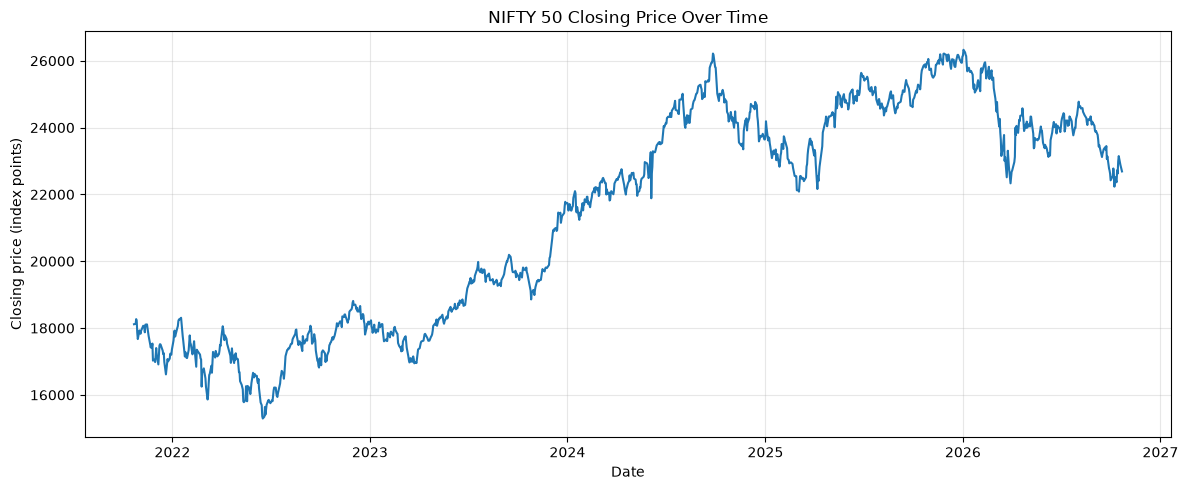

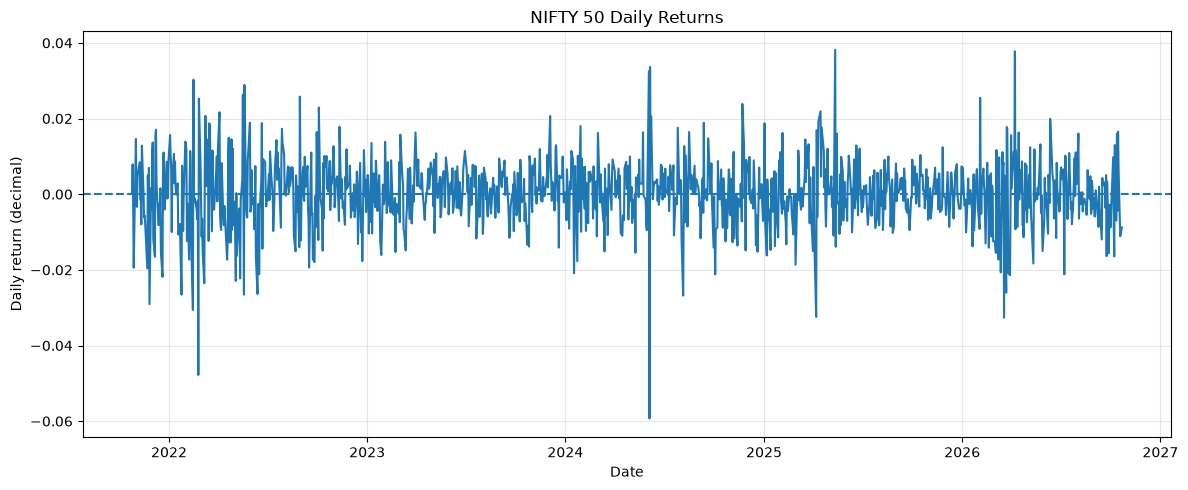

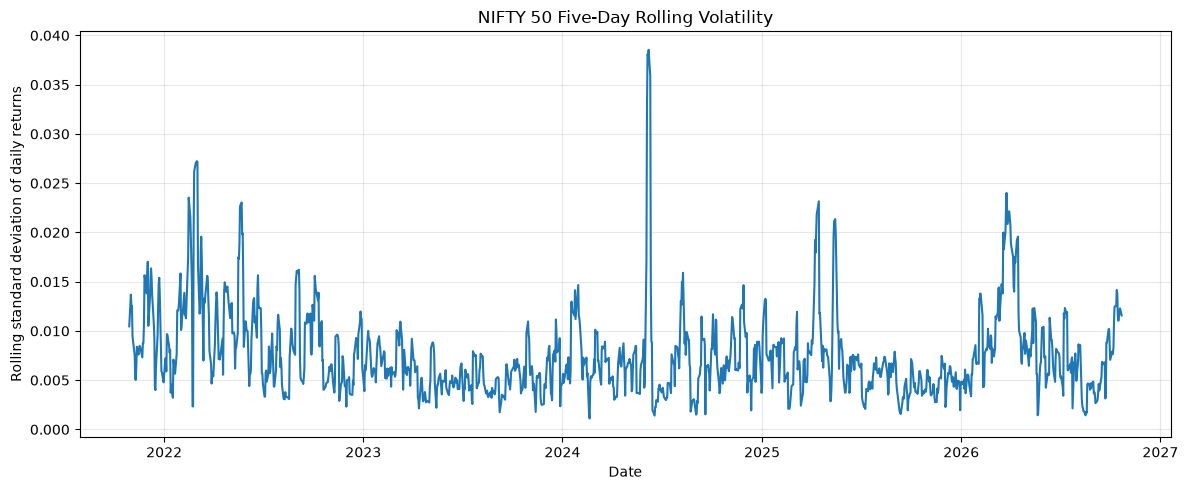

In [5]:

# Ensure prices are in chronological order.
prices = prices.sort_values("Date").reset_index(drop=True)

# Plot 1: NIFTY 50 closing price.
plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices["Close"])
plt.title("NIFTY 50 Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Closing price (index points)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 2: Daily percentage returns.
plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices["return_1d"])
plt.axhline(0, linestyle="--")
plt.title("NIFTY 50 Daily Returns")
plt.xlabel("Date")
plt.ylabel("Daily return (decimal)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Plot 3: Five-trading-day rolling volatility.
plt.figure(figsize=(12, 5))
plt.plot(prices["Date"], prices["volatility_5d"])
plt.title("NIFTY 50 Five-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Rolling standard deviation of daily returns")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


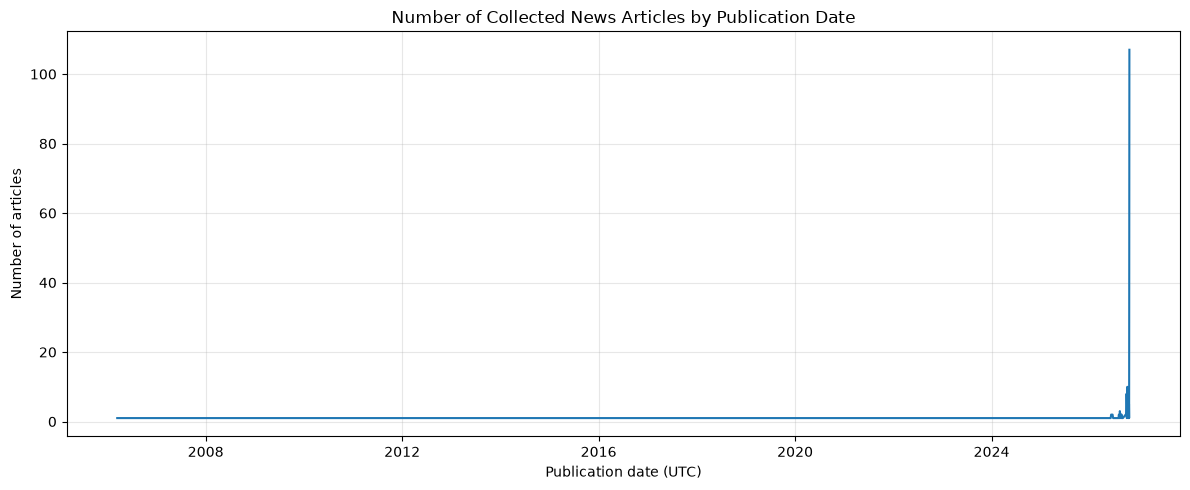

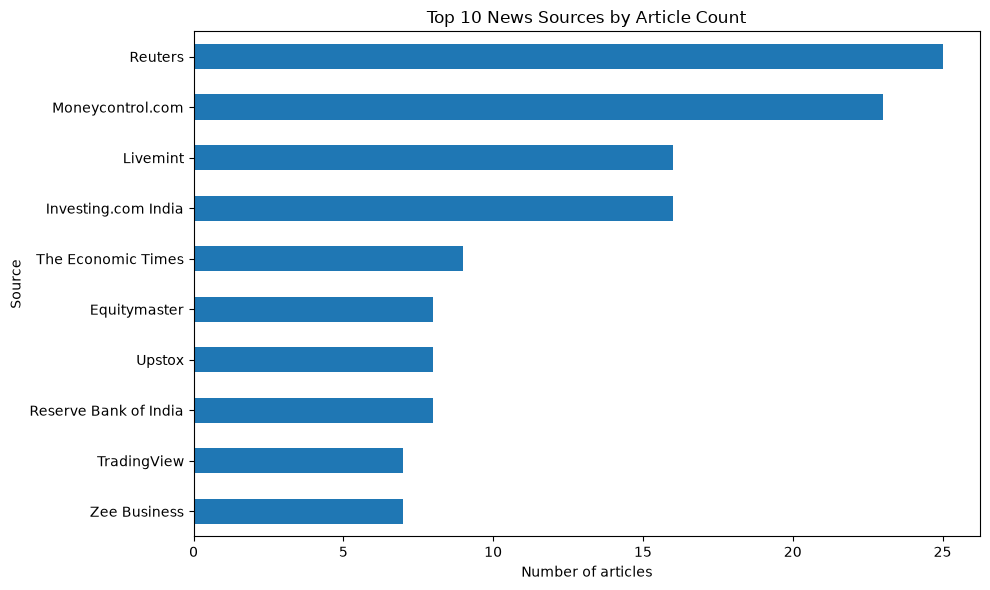

In [6]:
#for the news

# Ensure publication timestamps are parsed correctly.
news["published_at"] = pd.to_datetime(
    news["published_at"],
    errors="coerce",
    utc=True,
)

# Remove rows without usable publication dates for time-based analysis.
news_timed = news.dropna(subset=["published_at"]).copy()

# Count articles by publication date (UTC).
news_timed["publication_date"] = (
    news_timed["published_at"].dt.date
)

daily_news = (
    news_timed.groupby("publication_date")
    .size()
    .rename("article_count")
)

plt.figure(figsize=(12, 5))
daily_news.plot()
plt.title("Number of Collected News Articles by Publication Date")
plt.xlabel("Publication date (UTC)")
plt.ylabel("Number of articles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Most frequent news sources.
plt.figure(figsize=(10, 6))
news_timed["source"].value_counts().head(10).sort_values().plot(
    kind="barh"
)
plt.title("Top 10 News Sources by Article Count")
plt.xlabel("Number of articles")
plt.ylabel("Source")
plt.tight_layout()
plt.show()


,article_count
sentiment_label,
positive,106
neutral,100
negative,54
unclassified,6


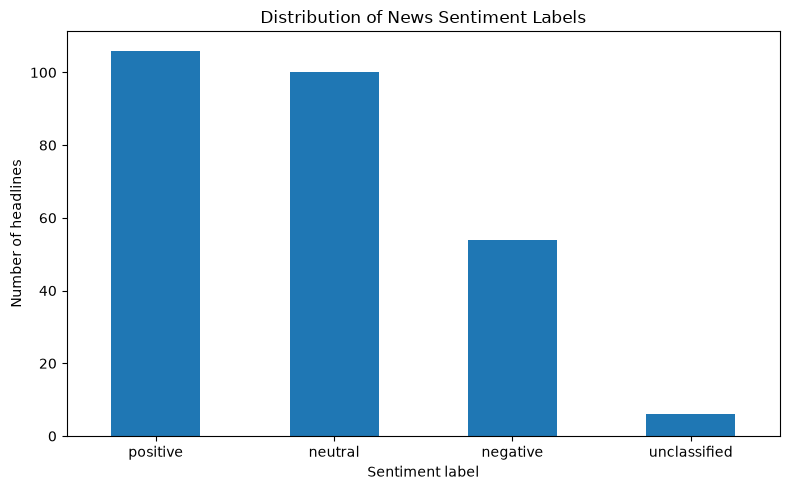

In [7]:

sentiment_counts = sentiment["sentiment_label"].value_counts()

display(sentiment_counts.to_frame("article_count"))

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind="bar")
plt.title("Distribution of News Sentiment Labels")
plt.xlabel("Sentiment label")
plt.ylabel("Number of headlines")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:

# Examine the publication-date range.
print("Earliest publication:", news_timed["published_at"].min())
print("Latest publication:", news_timed["published_at"].max())

print("\nArticles by publication year:")
display(
    news_timed["published_at"]
    .dt.year
    .value_counts()
    .sort_index()
    .rename("article_count")
    .to_frame()
)

print("\nArticles per publication date:")
display(
    daily_news.describe().to_frame("articles_per_day")
)

print("\nDates with the most articles:")
display(
    daily_news.sort_values(ascending=False).head(10)
    .to_frame("article_count")
)


Earliest publication: 2006-03-14 22:24:39+00:00
Latest publication: 2026-10-22 17:19:36+00:00

Articles by publication year:


,article_count
published_at,
2006,1
2011,1
2014,1
2016,1
2017,2
2018,1
2024,2
2025,1
2026,256



Articles per publication date:


,articles_per_day
count,63.000000
mean,4.222222
std,14.491871
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,107.000000



Dates with the most articles:


,article_count
publication_date,
2026-10-22,107
2026-10-21,48
2026-10-07,10
2026-10-01,8
2026-10-05,6
2026-10-12,6
2026-10-19,5
2026-10-16,4
2026-10-06,3


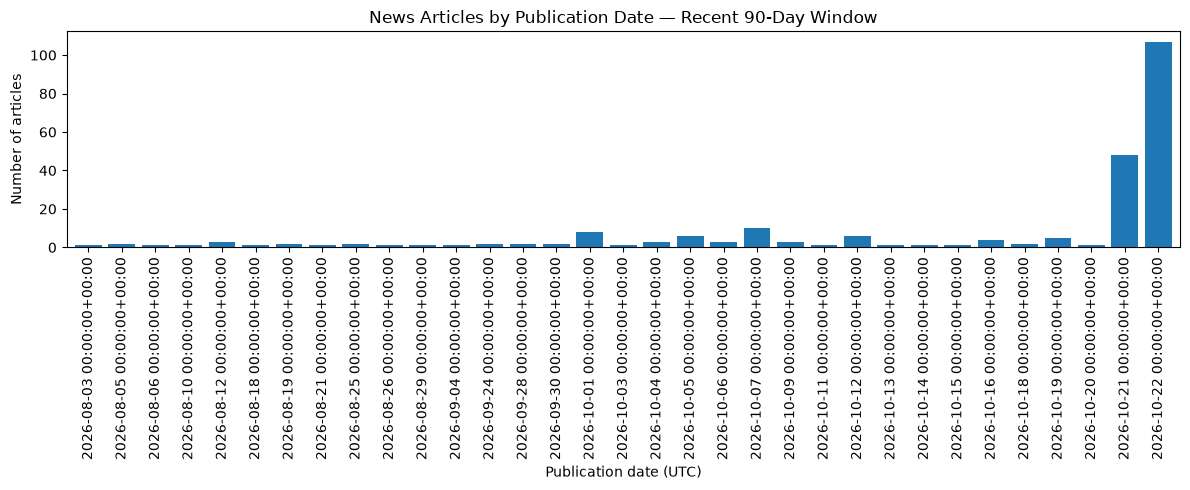

In [9]:

latest_date = news_timed["published_at"].max()
cutoff_date = latest_date - pd.Timedelta(days=90)

recent_news = news_timed[
    news_timed["published_at"] >= cutoff_date
].copy()

recent_daily_counts = (
    recent_news.assign(
        publication_date=recent_news["published_at"].dt.floor("D")
    )
    .groupby("publication_date")
    .size()
)

plt.figure(figsize=(12, 5))
recent_daily_counts.plot(kind="bar", width=0.8)
plt.title("News Articles by Publication Date — Recent 90-Day Window")
plt.xlabel("Publication date (UTC)")
plt.ylabel("Number of articles")
plt.tight_layout()
plt.show()


In [11]:

import requests
import pandas as pd

url = "https://api.gdeltproject.org/api/v2/doc/doc"

params = {
    "query": '("NIFTY" OR "Sensex" OR "Indian stock market")',
    "mode": "artlist",
    "format": "json",
    "timespan": "3months",
    "maxrecords": 10,
    "sort": "datedesc",
}

response = requests.get(url, params=params, timeout=30)

print("HTTP status:", response.status_code)
response.raise_for_status()

data = response.json()
articles = data.get("articles", [])

print("Articles returned:", len(articles))
print("Response keys:", list(data.keys()))

if articles:
    results = pd.DataFrame(articles)
    display(results[["seendate", "title", "domain", "url"]])
else:
    print("No articles returned. Response preview:")
    print(response.text[:1000])


HTTP status: 200
Articles returned: 0
Response keys: []
No articles returned. Response preview:
{}
